In [9]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import numpy as np


In [10]:
data = torch.load("cached_clip_embeddings.pth", map_location="cpu")

train_embs = data["embeddings"]["train"]
val_embs   = data["embeddings"]["val"]

train_labels = data["labels"]["train"]
val_labels   = data["labels"]["val"]


In [11]:
train_labels = train_labels.view(-1).long()
val_labels   = val_labels.view(-1).long()


In [12]:
print(train_embs.shape)     # (N, 512)
print(train_labels.shape)   # (N,)
print(train_labels.dtype)   # torch.int64


torch.Size([89996, 512])
torch.Size([89996])
torch.int64


In [13]:
batch_size = 128

train_loader = DataLoader(
    TensorDataset(train_embs, train_labels),
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    TensorDataset(val_embs, val_labels),
    batch_size=batch_size,
    shuffle=False
)


In [14]:
class LinearProbe(nn.Module):
    def __init__(self, in_dim, num_classes):
        super().__init__()
        self.fc = nn.Linear(in_dim, num_classes)

    def forward(self, x):
        return self.fc(x)


In [15]:
num_classes = len(torch.unique(train_labels))
model = LinearProbe(512, num_classes)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)


In [18]:
epochs = 40

for epoch in range(epochs):
    model.train()
    total_loss = 0

    for x, y in train_loader:
        optimizer.zero_grad()
        logits = model(x)
        loss = criterion(logits, y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    # validation
    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for x, y in val_loader:
            preds = model(x).argmax(dim=1)
            correct += (preds == y).sum().item()
            total += y.size(0)

    val_acc = 100 * correct / total
    print(f"Epoch [{epoch+1}/{epochs}]  Val Acc: {val_acc:.2f}%")


Epoch [1/40]  Val Acc: 90.57%
Epoch [2/40]  Val Acc: 90.64%
Epoch [3/40]  Val Acc: 90.69%
Epoch [4/40]  Val Acc: 90.69%
Epoch [5/40]  Val Acc: 90.76%
Epoch [6/40]  Val Acc: 90.83%
Epoch [7/40]  Val Acc: 90.80%
Epoch [8/40]  Val Acc: 90.76%
Epoch [9/40]  Val Acc: 90.80%
Epoch [10/40]  Val Acc: 90.81%
Epoch [11/40]  Val Acc: 90.97%
Epoch [12/40]  Val Acc: 90.87%
Epoch [13/40]  Val Acc: 90.92%
Epoch [14/40]  Val Acc: 90.94%
Epoch [15/40]  Val Acc: 90.97%
Epoch [16/40]  Val Acc: 91.07%
Epoch [17/40]  Val Acc: 91.08%
Epoch [18/40]  Val Acc: 91.00%
Epoch [19/40]  Val Acc: 91.03%
Epoch [20/40]  Val Acc: 91.03%
Epoch [21/40]  Val Acc: 91.11%
Epoch [22/40]  Val Acc: 91.13%
Epoch [23/40]  Val Acc: 91.16%
Epoch [24/40]  Val Acc: 91.18%
Epoch [25/40]  Val Acc: 91.15%
Epoch [26/40]  Val Acc: 91.24%
Epoch [27/40]  Val Acc: 91.24%
Epoch [28/40]  Val Acc: 91.16%
Epoch [29/40]  Val Acc: 91.21%
Epoch [30/40]  Val Acc: 91.20%
Epoch [31/40]  Val Acc: 91.31%
Epoch [32/40]  Val Acc: 91.26%
Epoch [33/40]  Va

In [19]:
torch.save(model.state_dict(), "linear_probe_final.pth")
print("Model saved successfully")


Model saved successfully


In [20]:
import torch
import torch.nn.functional as F

model.eval()

total_loss = 0.0
total_correct = 0
total_samples = 0

with torch.no_grad():
    for x, y in val_loader:   # or test_loader
        x, y = x.to(device), y.to(device)

        logits = model(x)
        loss = F.cross_entropy(logits, y)

        total_loss += loss.item() * y.size(0)
        preds = logits.argmax(dim=1)
        total_correct += (preds == y).sum().item()
        total_samples += y.size(0)

avg_loss = total_loss / total_samples
accuracy = 100.0 * total_correct / total_samples

print(f"Loss: {avg_loss:.4f}")
print(f"Accuracy: {accuracy:.2f}%")


Loss: 0.2659
Accuracy: 91.39%


In [24]:
model.eval()


LinearProbe(
  (fc): Linear(in_features=512, out_features=9, bias=True)
)

In [25]:
import torch.nn.functional as F

total_loss = 0.0
correct = 0
total = 0

with torch.no_grad():
    for x, y in val_loader:   # or test_loader if you have it
        logits = model(x)
        loss = F.cross_entropy(logits, y)
        
        total_loss += loss.item() * x.size(0)
        preds = logits.argmax(dim=1)
        correct += (preds == y).sum().item()
        total += y.size(0)

avg_loss = total_loss / total
accuracy = 100.0 * correct / total

print(f"Validation Loss: {avg_loss:.4f}")
print(f"Validation Accuracy: {accuracy:.2f}%")


Validation Loss: 0.2659
Validation Accuracy: 91.39%


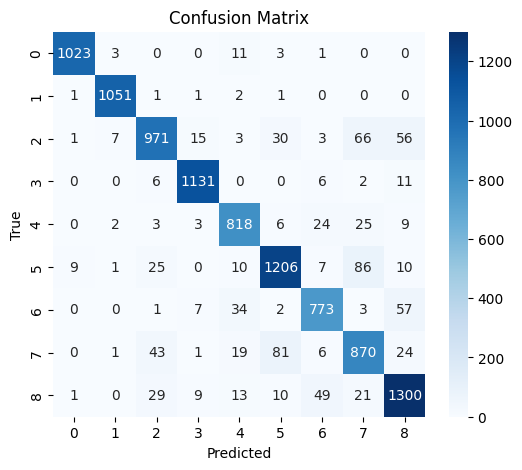

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()


<Axes: >

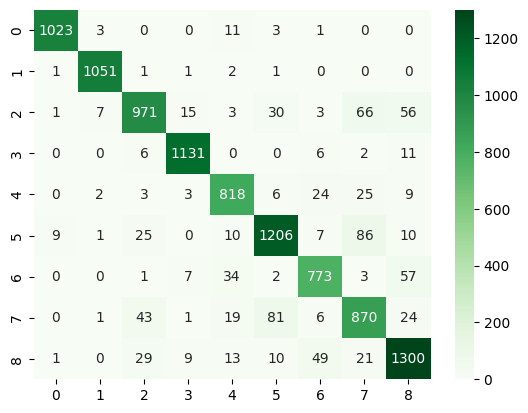

In [30]:
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens")


<Axes: >

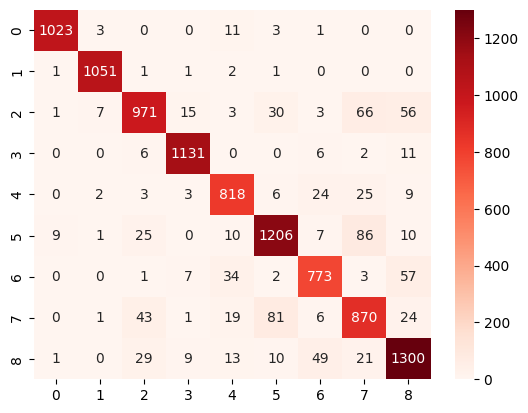

In [31]:
sns.heatmap(cm, annot=True, fmt="d", cmap="Reds")


<Axes: >

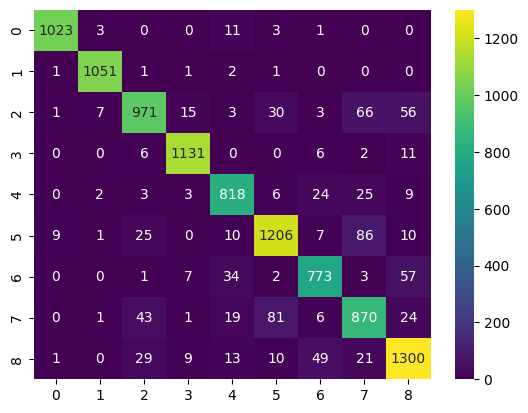

In [32]:
sns.heatmap(cm, annot=True, fmt="d", cmap="viridis")


In [34]:
class_acc = cm.diagonal() / cm.sum(axis=1) * 100

for i, acc in enumerate(class_acc):
    print(f"Class {i}: {acc:.2f}%")


Class 0: 98.27%
Class 1: 99.43%
Class 2: 84.29%
Class 3: 97.84%
Class 4: 91.91%
Class 5: 89.07%
Class 6: 88.14%
Class 7: 83.25%
Class 8: 90.78%


In [36]:
from sklearn.metrics import precision_score, recall_score, f1_score
import torch

model.eval()

all_preds = []
all_targets = []

with torch.no_grad():
    for x, y in val_loader:   # or test_loader if you have one
        logits = model(x)
        preds = torch.argmax(logits, dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_targets.extend(y.cpu().numpy())


In [37]:
precision = precision_score(all_targets, all_preds, average="macro")
recall = recall_score(all_targets, all_preds, average="macro")
f1 = f1_score(all_targets, all_preds, average="macro")

print(f"Precision: {precision*100:.2f}%")
print(f"Recall: {recall*100:.2f}%")
print(f"F1-score: {f1*100:.2f}%")


Precision: 91.45%
Recall: 91.44%
F1-score: 91.43%


In [38]:
from sklearn.metrics import classification_report

print(classification_report(all_targets, all_preds))


              precision    recall  f1-score   support

           0       0.99      0.98      0.99      1041
           1       0.99      0.99      0.99      1057
           2       0.90      0.84      0.87      1152
           3       0.97      0.98      0.97      1156
           4       0.90      0.92      0.91       890
           5       0.90      0.89      0.90      1354
           6       0.89      0.88      0.89       877
           7       0.81      0.83      0.82      1045
           8       0.89      0.91      0.90      1432

    accuracy                           0.91     10004
   macro avg       0.91      0.91      0.91     10004
weighted avg       0.91      0.91      0.91     10004

